In [3]:
import xarray as xr
linea_base_no2 = xr.open_dataset("mystorage/Linea_Base_NO2_AMG.nc")["NO2"]
linea_base_ch4 = xr.open_dataset("mystorage/Linea_Base_CH4_AMG.nc")["CH4"]
print("Línea base cargada")

Línea base cargada


In [4]:
cubo_no2 = xr.open_dataset("mystorage/Cubo_NO2_Final.nc")["NO2"]
cubo_ch4 = xr.open_dataset("mystorage/Cubo_CH4_Final.nc")["CH4"]

print("Cubos cargados")

Cubos cargados


In [ ]:

cds_url = "https://cds.climate.copernicus.eu/api"
cds_key = "..." 
ruta_credenciales = "/home/jovyan/.cdsapirc"

with open(ruta_credenciales, 'w') as f:
    f.write(f"url: {cds_url}\n")
    f.write(f"key: {cds_key}\n")

print(f"Credenciales configuradas, creadas en: {ruta_credenciales}")


import cdsapi
from dateutil.relativedelta import relativedelta
from datetime import datetime

c = cdsapi.Client()

area_amg = [14.9147, -90.7626, 14.2423, -90.2119]

def descargar_viento_mensual(year, month, folder_name="Viento_ERA5_Historico"):
    file_name = os.path.join(folder_name, f"ERA5_Viento_{year}_{month:02d}.nc")
    
    print(f" -> Solicitando procesamiento para {year}-{month:02d}...")
    
    c.retrieve(
        'reanalysis-era5-single-levels',
        {
            'product_type': 'reanalysis',
            'format': 'netcdf',
            'variable': [
                '10m_u_component_of_wind',
                '10m_v_component_of_wind',
            ],
            'year': str(year),
            'month': f"{month:02d}",
            'day': [f"{d:02d}" for d in range(1, 32)],
            'time': [f"{h:02d}:00" for h in range(24)],
            'area': area_amg,
        },
        file_name
    )
    print(f"Archivo guardado: {file_name}")

os.makedirs("Viento_ERA5_Historico", exist_ok=True)

start_period = datetime(2018, 7, 1)
end_period = datetime(2025, 7, 1)
current_date = start_period

print("Iniciando extracción.")

while current_date < end_period:
    year = current_date.year
    month = current_date.month
    
    try:
        descargar_viento_mensual(year, month)
    except Exception as e:
        print(f"    [!] Error al procesar {year}-{month:02d}: {e}")
        
    current_date += relativedelta(months=1)

print("Extracción de datos de viento completada")


In [ ]:
import xarray as xr

print("Cargando archivos NetCDF...")


viento_dataset = xr.open_mfdataset("mystorage/Viento_ERA5_Historico/ERA5_Viento_*.nc", combine='by_coords')

print("Alineando temporalidad a promedios mensuales:")

viento_cubo = viento_dataset.resample(valid_time="1MS").mean()

print("Cubo de datos de viento construido")

viento_cubo

In [ ]:
import geopandas as gpd

poligono_amg = gpd.read_file("mystorage/amg_limites.geojson")
poligono_amg = poligono_amg.to_crs("EPSG:4326")

viento_cubo.rio.write_crs("EPSG:4326", inplace=True)
print("Aplicando enmascaramiento espacial.")

viento_cubo_masked = viento_cubo.rio.clip(poligono_amg.geometry, poligono_amg.crs, drop=False)

print("Enmascaramiento completado")

viento_cubo_masked.to_netcdf("mystorage/Cubo_Viento_AMG_Final.nc")
print("Cubo guardado como 'Cubo_Viento_AMG_Final.nc'")

viento_cubo_masked

In [ ]:
viento_linea_base = viento_cubo_masked.mean(dim="valid_time", skipna=True)
viento_linea_base.to_netcdf("mystorage/Linea_Base_Viento_AMG.nc")
print("Archivo guardado como 'Linea_Base_Viento_AMG.nc'")
viento_linea_base

In [1]:
import xarray as xr
cubo_viento = xr.open_dataset("mystorage/Cubo_Viento_AMG_Final.nc")

In [2]:
linea_base_viento = xr.open_dataset("mystorage/Linea_Base_Viento_AMG.nc")

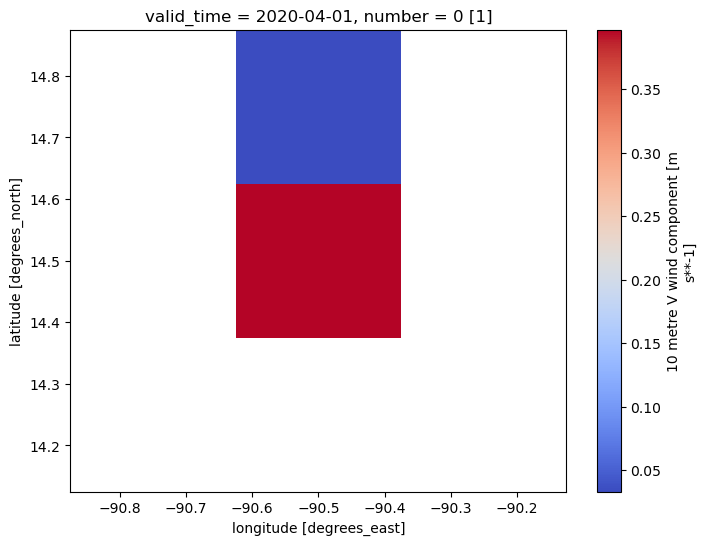

In [4]:
cubo_viento['v10'].sel(valid_time="2020-04-01").plot(cmap="coolwarm", size=6)

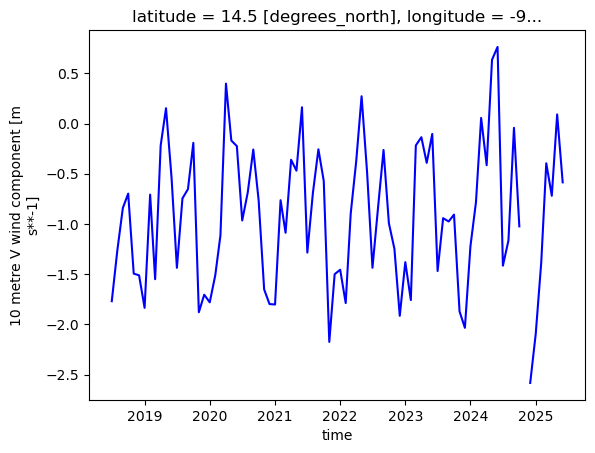

In [5]:
latitud_hotspot = 14.50644994392857
longitud_hotspot = -90.624926285

cubo_viento['v10'].sel(longitude=longitud_hotspot, latitude=latitud_hotspot, method="nearest").plot(color="blue")

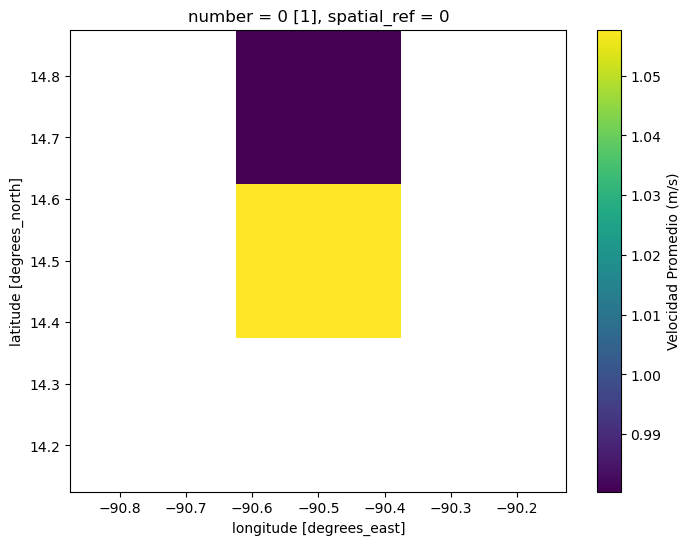

In [6]:
import numpy as np

magnitud_viento = np.sqrt(linea_base_viento['u10']**2 + linea_base_viento['v10']**2)

magnitud_viento.plot(cmap="viridis", size=6, cbar_kwargs={'label': 'Velocidad Promedio (m/s)'})

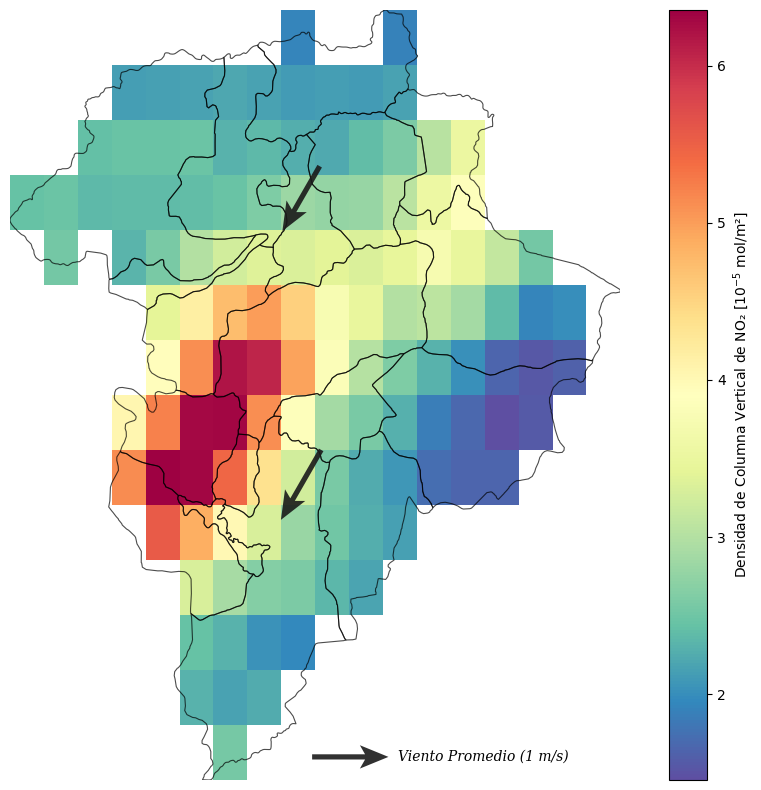

In [23]:
import matplotlib.pyplot as plt
import geopandas as gpd
import xarray as xr
cubo_viento = xr.open_dataset("mystorage/Cubo_Viento_AMG_Final.nc")
viento_uncut = cubo_viento.mean(dim="valid_time", skipna=True)

poligono_amg = gpd.read_file("mystorage/amg_limites.geojson")
poligono_amg = poligono_amg.to_crs("EPSG:4326")

fig, ax = plt.subplots(figsize=(10, 8))

(linea_base_no2 * 1e5).plot(
    ax=ax,
    cmap="Spectral_r",
    cbar_kwargs={'label': 'Densidad de Columna Vertical de NO₂ [$10^{-5}$ mol/m²]'}
)

poligono_amg.plot(
    ax=ax,
    facecolor="none",       
    edgecolor="black",      
    linewidth=0.8,
    alpha=0.7
)

U = viento_uncut['u10'].values
V = viento_uncut['v10'].values
X = viento_uncut.longitude.values
Y = viento_uncut.latitude.values

q = ax.quiver(
    X, Y, U, V,
    color='#1A1A1A',    
    pivot='middle',
    scale=8,           
    width=0.0085,       
    headwidth=4.5,
    headlength=5.5,
    alpha=0.9,
    zorder=5            
)

ax.quiverkey(
    q, X=0.62, Y=0.03, U=1,
    label='Viento Promedio (1 m/s)',
    labelpos='E',
    coordinates='axes',
    fontproperties={'family':'serif', 'style': 'italic','size': 10, 'weight': 'light'}
)

ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(
    "", 
    fontsize=14, fontweight="bold", pad=15
)

plt.tight_layout()
plt.savefig("mapa_linea_base_no2_viento.png", dpi=300, bbox_inches='tight')

plt.show()

Coeficiente de Correlación de Pearson (r): -0.3154
Valor p: 3.6829e-03


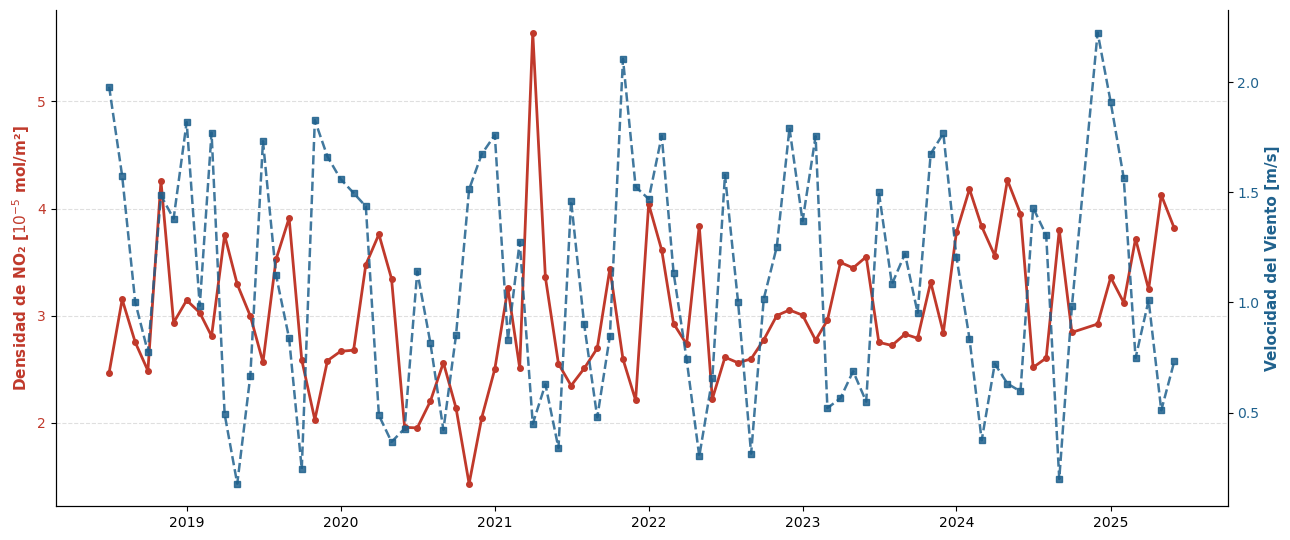

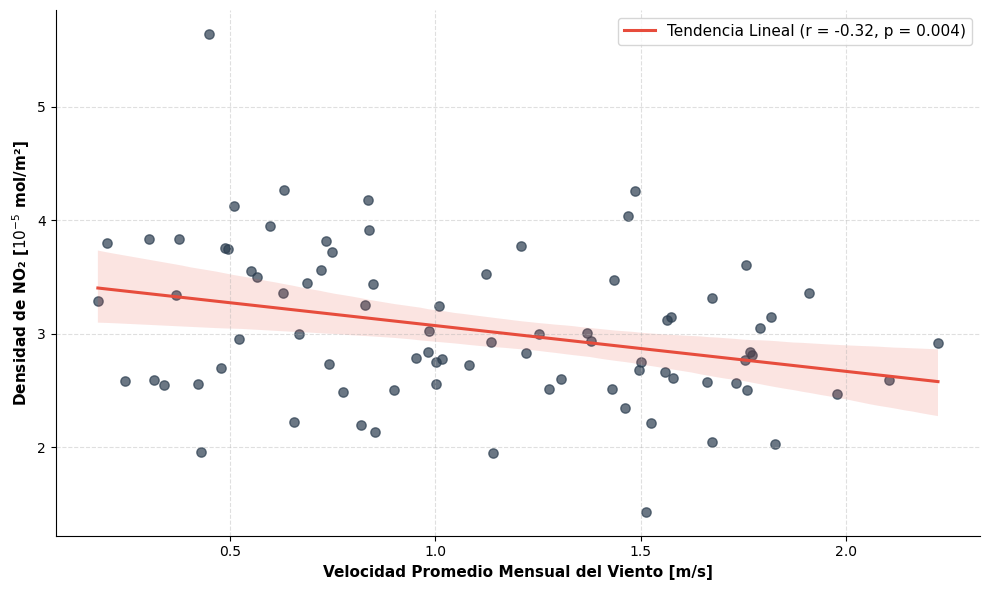

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy.stats import pearsonr

if 'valid_time' in cubo_viento.dims or 'valid_time' in cubo_viento.coords:
    cubo_viento = cubo_viento.rename({'valid_time': 'time'})
    
velocidad_3d = np.sqrt(cubo_viento['u10']**2 + cubo_viento['v10']**2)

ts_viento = velocidad_3d.mean(dim=['longitude', 'latitude'], skipna=True)
ts_no2 = cubo_no2.mean(dim=['x', 'y'], skipna=True)

df_viento = ts_viento.to_dataframe(name='velocidad_viento').reset_index()[['time', 'velocidad_viento']]
df_no2 = ts_no2.to_dataframe(name='no2').reset_index()[['time', 'no2']]

df_estancamiento = pd.merge(df_no2, df_viento, on='time').dropna()
df_estancamiento['no2_escalado'] = df_estancamiento['no2'] * 1e5

r_val, p_val = pearsonr(df_estancamiento['velocidad_viento'], df_estancamiento['no2_escalado'])

print(f"Coeficiente de Correlación de Pearson (r): {r_val:.4f}")
print(f"Valor p: {p_val:.4e}")
fig1, ax1 = plt.subplots(figsize=(13, 5.5))

color_no2 = '#C0392B'
color_viento = '#1F618D'

ax1.plot(df_estancamiento['time'], df_estancamiento['no2_escalado'], 
         color=color_no2, marker='o', markersize=4, linewidth=2, label='Concentración de NO₂')
ax1.set_ylabel(r'Densidad de NO₂ [$10^{-5}$ mol/m²]', color=color_no2, fontsize=11, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_no2)
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.grid(axis='y', linestyle='--', alpha=0.4)
ax1.spines['top'].set_visible(False)

ax2 = ax1.twinx()
ax2.plot(df_estancamiento['time'], df_estancamiento['velocidad_viento'], 
         color=color_viento, linestyle='--', marker='s', markersize=4, linewidth=1.8, alpha=0.85, label='Velocidad del Viento (10m)')
ax2.set_ylabel('Velocidad del Viento [m/s]', color=color_viento, fontsize=11, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_viento)
ax2.spines['top'].set_visible(False)

ax1.set_title('', 
              fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.savefig('Dinamica_Temporal_NO2_Viento.png', dpi=300, bbox_inches='tight')
plt.show()

fig2, ax3 = plt.subplots(figsize=(10, 6))

sns.regplot(
    data=df_estancamiento, x='velocidad_viento', y='no2_escalado', ax=ax3,
    scatter_kws={'alpha': 0.7, 'color': '#2C3E50', 's': 45},
    line_kws={'color': '#E74C3C', 'linewidth': 2.2, 'label': f'Tendencia Lineal (r = {r_val:.2f}, p = {p_val:.3f})'}
)

ax3.set_title('', 
              fontsize=13, fontweight='bold', pad=12)
ax3.set_xlabel('Velocidad Promedio Mensual del Viento [m/s]', fontsize=11, fontweight='bold')
ax3.set_ylabel(r'Densidad de NO₂ [$10^{-5}$ mol/m²]', fontsize=11, fontweight='bold')

ax3.grid(True, linestyle='--', alpha=0.4)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.legend(loc='upper right', frameon=True, fontsize=11)

plt.tight_layout()
plt.savefig('Regresion_Estancamiento_NO2_Viento.png', dpi=300, bbox_inches='tight')
plt.show()

In [37]:
!pip install windrose

Procesando vectores direccionales y concentraciones de NO₂...


/tmp/ipykernel_236/3598299499.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


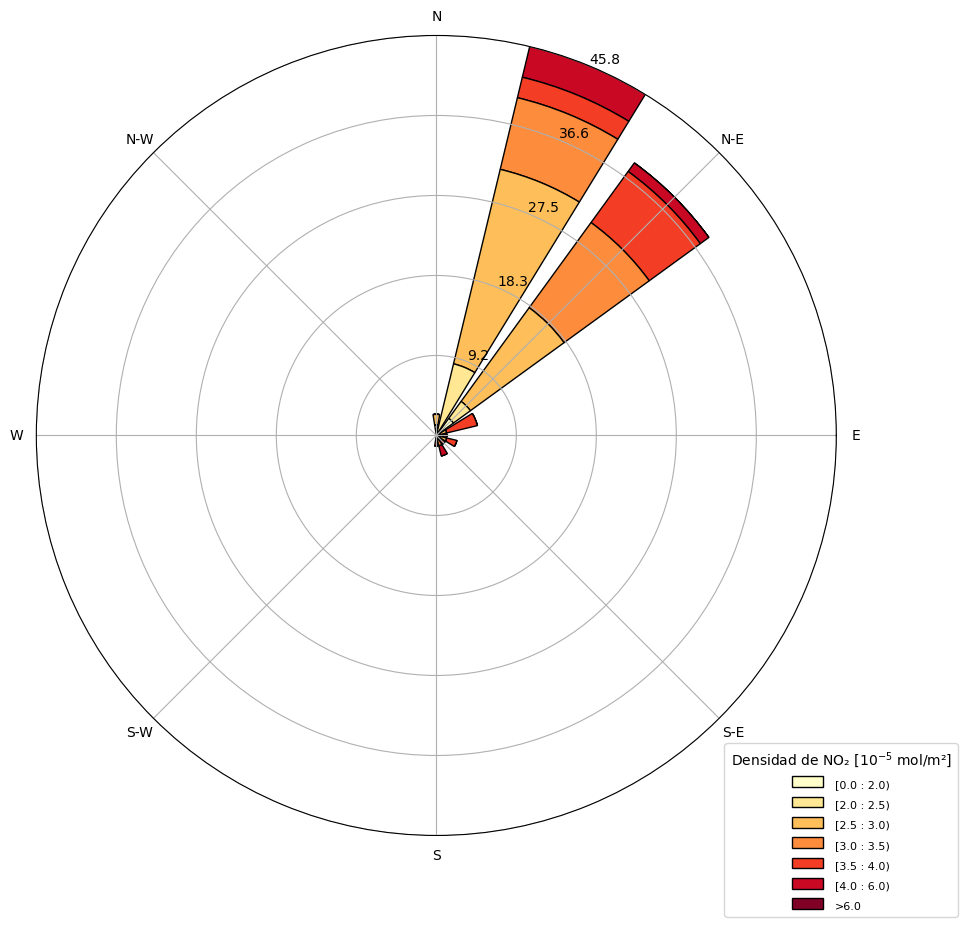

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from windrose import WindroseAxes

print("Procesando vectores direccionales y concentraciones de NO₂...")

ts_u = cubo_viento['u10'].mean(dim=['longitude', 'latitude'], skipna=True)
ts_v = cubo_viento['v10'].mean(dim=['longitude', 'latitude'], skipna=True)
ts_no2 = cubo_no2.mean(dim=['x', 'y'], skipna=True) * 1e5

df_rosa = pd.DataFrame({
    'time': pd.to_datetime(ts_no2.time.values),
    'no2_escalado': ts_no2.values,
    'u_wind': ts_u.values,
    'v_wind': ts_v.values
}).dropna()

df_rosa['direccion_viento'] = (180 + np.degrees(np.arctan2(df_rosa['u_wind'], df_rosa['v_wind']))) % 360

fig = plt.figure(figsize=(10, 10))
ax = WindroseAxes.from_ax(fig=fig)

ax.bar(
    direction=df_rosa['direccion_viento'], 
    var=df_rosa['no2_escalado'], 
    normed=True,          
    opening=0.8,         
    edgecolor='black',    
    cmap=plt.cm.YlOrRd,   
    bins=[0, 2.0, 2.5, 3.0, 3.5, 4.0, 6.0] 
)

ax.set_legend(
    title=r"Densidad de NO₂ [$10^{-5}$ mol/m²]", 
    loc='lower right', 
    bbox_to_anchor=(1.15, -0.1),
    fontsize=11
)

plt.title("", 
          fontsize=15, fontweight='bold')

plt.tight_layout()
plt.savefig('Pollution_Wind_Rose_NO2.png', dpi=300, bbox_inches='tight')
plt.show()

Llegada del viento (Barlovento / Lado Este) : 6.06 x 10^-5 mol/m²
Acumulación vehicular (Sotavento / Lado Oeste) : 6.24 x 10^-5 mol/m²
Aumento de contaminación a favor del viento : +3.0%



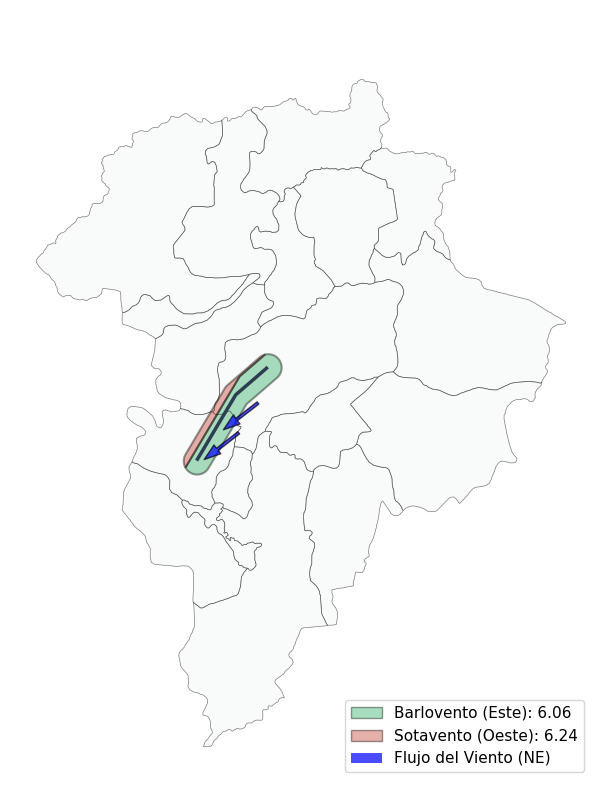

In [6]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from shapely.geometry import LineString
from shapely.affinity import scale
from shapely.ops import split

poligono_amg = gpd.read_file("mystorage/amg_limites.geojson")
poligono_amg = poligono_amg.to_crs("EPSG:4326")

coordenadas_corredor = [
    (-90.521811, 14.624648),
    (-90.535576, 14.613063), 
    (-90.555191, 14.596728), 
    (-90.595889, 14.530440)
]
linea_ca9 = LineString(coordenadas_corredor)
gdf_linea = gpd.GeoDataFrame(index=[0], geometry=[linea_ca9], crs="EPSG:4326")

buffer_utm = gdf_linea.to_crs("EPSG:32615").buffer(1500)
gdf_buffer = gpd.GeoDataFrame(geometry=buffer_utm, crs="EPSG:32615").to_crs("EPSG:4326")
poligono_buffer = gdf_buffer.geometry.iloc[0]

linea_extendida = scale(linea_ca9, xfact=2.0, yfact=2.0)
mitades = split(poligono_buffer, linea_extendida)

poligono_este = None
poligono_oeste = None

for poly in mitades.geoms:
    if poligono_este is None:
        poligono_este = poly
        poligono_oeste = poly
    else:
        if poly.bounds[0] > poligono_oeste.bounds[0]:
            poligono_este = poly
        else:
            poligono_oeste = poly

gdf_barlovento = gpd.GeoDataFrame(index=[0], geometry=[poligono_este], crs="EPSG:4326")
gdf_sotavento = gpd.GeoDataFrame(index=[0], geometry=[poligono_oeste], crs="EPSG:4326")

recorte_barlovento = linea_base_no2.rio.clip(gdf_barlovento.geometry, gdf_barlovento.crs, drop=True)
recorte_sotavento = linea_base_no2.rio.clip(gdf_sotavento.geometry, gdf_sotavento.crs, drop=True)

media_barlovento = recorte_barlovento.mean(skipna=True).item() * 1e5
media_sotavento = recorte_sotavento.mean(skipna=True).item() * 1e5
diferencia_arrastre = ((media_sotavento / media_barlovento) - 1) * 100

print(f"Llegada del viento (Barlovento / Lado Este) : {media_barlovento:.2f} x 10^-5 mol/m²")
print(f"Acumulación vehicular (Sotavento / Lado Oeste) : {media_sotavento:.2f} x 10^-5 mol/m²")
print(f"Aumento de contaminación a favor del viento : +{diferencia_arrastre:.1f}%\n")

fig, ax = plt.subplots(figsize=(10, 8))

poligono_amg.plot(ax=ax, facecolor="#F4F6F6", edgecolor="black", linewidth=0.5, alpha=0.5)

gdf_barlovento.plot(ax=ax, facecolor="#27AE60", edgecolor="black", linewidth=1.5, alpha=0.4, label="Barlovento (Viento limpio)")
gdf_sotavento.plot(ax=ax, facecolor="#C0392B", edgecolor="black", linewidth=1.5, alpha=0.4, label="Sotavento (Arrastre tóxico)")

gdf_linea.plot(ax=ax, color="#2C3E50", linewidth=2.5)

ax.annotate('', xy=(-90.57, 14.56), xytext=(-90.53, 14.59),
            arrowprops=dict(facecolor='blue', shrink=0.05, width=2, headwidth=8, alpha=0.7))
ax.annotate('', xy=(-90.59, 14.53), xytext=(-90.55, 14.56),
            arrowprops=dict(facecolor='blue', shrink=0.05, width=2, headwidth=8, alpha=0.7))

ax.set_title(" ", fontsize=14, fontweight='bold', pad=15)
ax.set_axis_off()

leyenda_barlo = mpatches.Patch(facecolor='#27AE60', alpha=0.4, edgecolor='black', label=f'Barlovento (Este): {media_barlovento:.2f}')
leyenda_sota = mpatches.Patch(facecolor='#C0392B', alpha=0.4, edgecolor='black', label=f'Sotavento (Oeste): {media_sotavento:.2f}')
leyenda_viento = mpatches.Patch(facecolor='blue', alpha=0.7, label='Flujo del Viento (NE)')
ax.legend(handles=[leyenda_barlo, leyenda_sota, leyenda_viento], loc='lower right', frameon=True, fontsize=11)

plt.tight_layout()
plt.savefig("Efecto_Arrastre_CA9.png", dpi=300, bbox_inches='tight')
plt.show()